# Solutions · 12 · Membrane gas separation

Worked solutions to the exercises of [notebook 12](../notebooks/12_membrane_gas_separation.ipynb). Try each exercise
yourself before reading its solution - the learning happens in the attempt. Solutions are one way to
answer each question; other correct approaches exist.

In [1]:
try:                      # on Google Colab (or anywhere engsep is missing): install it from GitHub
    import engsep
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engsep"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import integrate, optimize
from engsep import datasets
from engsep import membranes as mb
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Exercise 1

Hydrogen recovery from a refinery purge (60 % H2, 40 % CH4) with polysulfone (H2/CH4 selectivity from the table) at a pressure ratio of 0.1: plot permeate H2 purity and H2 recovery against stage cut (cross flow). Where would you operate for 95 % purity, and what recovery does that give?

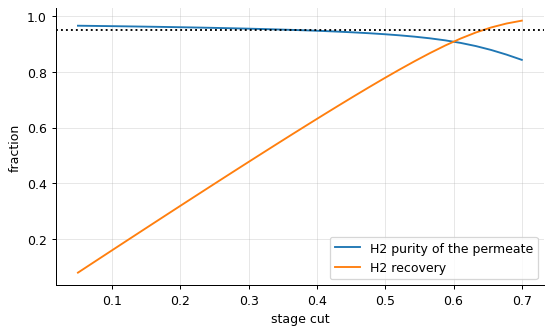

H2/CH4 selectivity 22: 95 % purity holds up to a stage cut of 0.34, recovering 54% of the hydrogen


In [2]:
d = pd.read_csv(datasets.path("gas_permeabilities.csv"), comment="#")
ps = d[d.polymer == "polysulfone"].iloc[0]
alpha = ps.H2 / ps.CH4
thetas = np.linspace(0.05, 0.7, 30)
res = [mb.cross_flow(alpha, 0.60, 0.1, t) for t in thetas]
purity = np.array([r["y_permeate"] for r in res]); recovery = thetas * purity / 0.60
plt.plot(thetas, purity, label="H2 purity of the permeate"); plt.plot(thetas, recovery, label="H2 recovery"); plt.axhline(0.95, color="k", ls=":"); plt.xlabel("stage cut"); plt.ylabel("fraction"); plt.legend(); plt.show()
i = np.nonzero(purity >= 0.95)[0]
print(f"H2/CH4 selectivity {alpha:.0f}: 95 % purity holds up to a stage cut of {thetas[i[-1]]:.2f}, recovering {recovery[i[-1]]:.0%} of the hydrogen")

With a selectivity of 22 the permeate stays above 95 % hydrogen only up to a stage cut of about a third,
recovering little more than half the hydrogen; pushing the cut further dilutes the permeate with methane. Purity and
recovery trade against each other along the curve, and the plant picks the point the hydrogen is worth.

## Exercise 2

Two-stage biogas upgrading: the permeate of the first stage (polyimide) is recompressed and fed to a second stage, whose retentate is recycled to the feed. Estimate the methane loss with and without the second stage.

In [3]:
alpha = float(d[d.polymer.str.startswith("polyimide")].iloc[0]["CO2"] / d[d.polymer.str.startswith("polyimide")].iloc[0]["CH4"])
x_f, r = 0.40, 0.1
one = mb.cross_flow(alpha, x_f, r, 0.45)
loss_one = 0.45 * (1 - one["y_permeate"]) / (1 - x_f)
# second stage on the permeate: its retentate (methane-rich) is recycled; approximate the steady state by iterating the mixed feed
feed_x, feed_F = x_f, 1.0
for _ in range(50):
    s1 = mb.cross_flow(alpha, feed_x, r, 0.45)
    perm1 = 0.45 * feed_F
    s2 = mb.cross_flow(alpha, s1["y_permeate"], r, 0.6)
    ret2 = perm1 * (1 - 0.6)                                            # recycled to the feed
    feed_F_new = 1.0 + ret2
    feed_x_new = (1.0 * x_f + ret2 * s2["x_retentate"]) / feed_F_new
    if abs(feed_x_new - feed_x) < 1e-10:
        break
    feed_x, feed_F = feed_x_new, feed_F_new
loss_two = perm1 * 0.6 * (1 - s2["y_permeate"]) / (1 - x_f)
print(f"single stage: methane lost {loss_one:.1%}; two stages with recycle: {loss_two:.1%} (second-stage permeate {s2['y_permeate']:.3f} CO2)")

single stage: methane lost 13.5%; two stages with recycle: 0.3% (second-stage permeate 0.994 CO2)


A second stage on the first permeate recovers most of the methane that slipped through and returns it to
the feed: the loss falls from about a tenth to well under one percent, at the cost of recompressing the
first permeate. Two-stage membrane cascades are how biogas upgrading meets pipeline methane recoveries.

## Exercise 3

**Implement it yourself:** integrate the cross-flow model yourself (dL/dV = -1, d(Lx)/dV = -y with the local flux ratio) with solve_ivp and reproduce `membranes.cross_flow` for alpha = 5.6, r = 0.1, theta = 0.3.

In [4]:
alpha, r, theta, x_f = 5.6, 0.1, 0.3, 0.21
def local_y(x):
    return optimize.brentq(lambda y: y / (1 - y) - alpha * (x - r * y) / ((1 - x) - r * (1 - y)), x + 1e-12, 1 - 1e-12)
sol = integrate.solve_ivp(lambda v, s: [-1.0, -(local_y(s[1]) - s[1]) / s[0]], (0, theta), [1.0, x_f], rtol=1e-9, atol=1e-12, max_step=theta / 200)
L_out, x_out = sol.y[0][-1], sol.y[1][-1]
print(f"by hand: y = {(x_f - L_out * x_out) / theta:.5f}, x = {x_out:.5f}; library: {mb.cross_flow(alpha, x_f, r, theta)['y_permeate']:.5f}, {mb.cross_flow(alpha, x_f, r, theta)['x_retentate']:.5f}")

by hand: y = 0.44586, x = 0.10892; library: 0.44586, 0.10892


The cross-flow model is two ODEs along the membrane with the local flux ratio solved at each step; the hand
integration reproduces the library to five decimals.